# Sobol — Both Pooling (fac=1, amb=1)

Sensitivity analysis on T1 mortality.


In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RESULTS_PATH = _root / "data_cluster/saltelli_with_wrong_pooling_columns/results.csv"
df = pd.read_csv(RESULTS_PATH)
print(f"Loaded {len(df)} runs")

UNCERTAINTIES = ["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min", "bcas_rate", "waves_per_day", "wave_duration_min"]
from SALib.analyze import sobol as sobol_analyze

sub = df[(df["facility_eligibility"] == 1) & (df["ambulance_eligibility"] == 1)].sort_values("scenario").reset_index(drop=True)
print(f"Policy: Both Pooling (fac=1, amb=1), {len(sub)} runs")

OUTCOME = "death_rate_T1_BCAS"

# EMA Sobol sampler orders parameters alphabetically
BOUNDS_MAP = dict(zip(UNCERTAINTIES, [[10, 20], [15, 35], [0.01, 0.07], [1, 6], [1, 60]]))
UNCERTAINTIES_SORTED = sorted(UNCERTAINTIES)
BOUNDS_SORTED = [BOUNDS_MAP[u] for u in UNCERTAINTIES_SORTED]

problem = {
    "num_vars": len(UNCERTAINTIES),
    "names": UNCERTAINTIES_SORTED,
    "bounds": BOUNDS_SORTED,
}

N = len(sub) // (2 * problem["num_vars"] + 2)
print(f"Inferred N = {N}")
print(f"Expected Saltelli rows: {N * (2 * problem['num_vars'] + 2)}")
print(f"Actual rows: {len(sub)}")


Loaded 98304 runs


Policy: Both Pooling (fac=1, amb=1), 24576 runs
Inferred N = 2048
Expected Saltelli rows: 24576
Actual rows: 24576


## S1 and ST


                           ST   ST_conf
bcas_rate            0.498423  0.064228
ccp_r1_inter_bn_min  0.109941  0.017709
ccp_r1_same_bn_min   0.251016  0.027219
wave_duration_min    0.395108  0.049620
waves_per_day        0.541680  0.047527
                           S1   S1_conf
bcas_rate            0.123109  0.037062
ccp_r1_inter_bn_min  0.013157  0.021024
ccp_r1_same_bn_min   0.086643  0.031352
wave_duration_min    0.101593  0.041580
waves_per_day        0.151428  0.046972
                                                 S2   S2_conf
(bcas_rate, ccp_r1_inter_bn_min)           0.005380  0.059509
(bcas_rate, ccp_r1_same_bn_min)            0.024973  0.071944
(bcas_rate, wave_duration_min)             0.038404  0.064908
(bcas_rate, waves_per_day)                 0.154967  0.079874
(ccp_r1_inter_bn_min, ccp_r1_same_bn_min)  0.020004  0.030337
(ccp_r1_inter_bn_min, wave_duration_min)   0.002323  0.029374
(ccp_r1_inter_bn_min, waves_per_day)       0.009626  0.032910
(ccp_r1_same_bn_min, wav

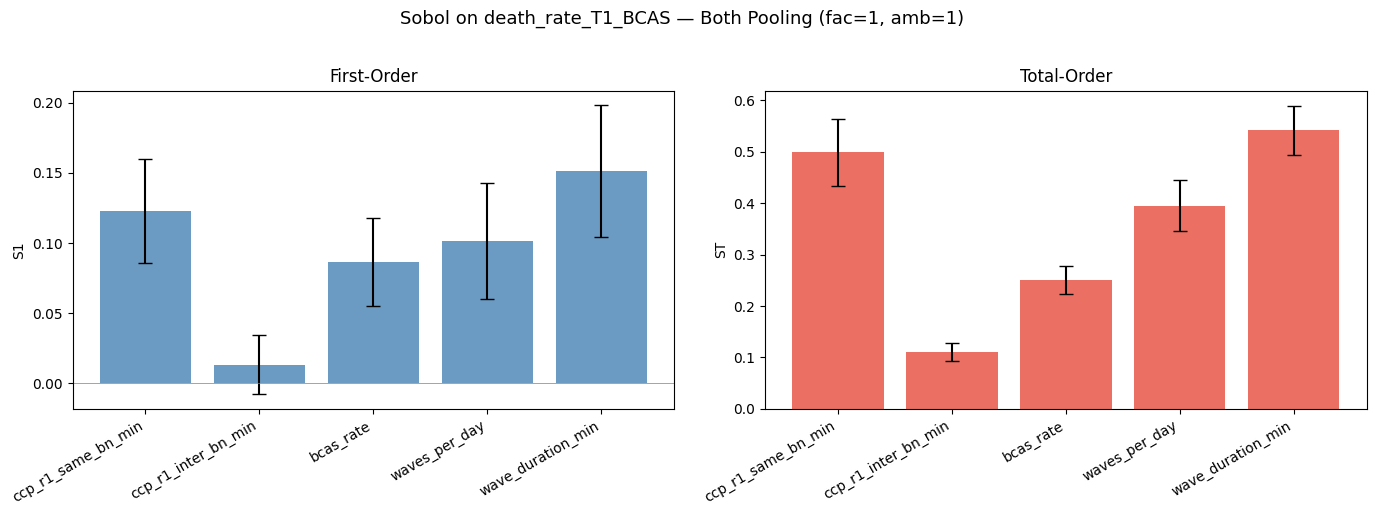

                        S1  S1_conf     ST  ST_conf
ccp_r1_same_bn_min  0.1231   0.0371 0.4984   0.0642
ccp_r1_inter_bn_min 0.0132   0.0210 0.1099   0.0177
bcas_rate           0.0866   0.0314 0.2510   0.0272
waves_per_day       0.1016   0.0416 0.3951   0.0496
wave_duration_min   0.1514   0.0470 0.5417   0.0475


In [2]:
Si = sobol_analyze.analyze(problem, sub[OUTCOME].values, calc_second_order=True, print_to_console=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x_pos = np.arange(len(UNCERTAINTIES))

axes[0].bar(x_pos, Si["S1"], yerr=Si["S1_conf"], capsize=5, color="steelblue", alpha=0.8)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(UNCERTAINTIES, rotation=30, ha="right")
axes[0].set_ylabel("S1")
axes[0].set_title("First-Order")
axes[0].axhline(0, color="grey", linewidth=0.5)

axes[1].bar(x_pos, Si["ST"], yerr=Si["ST_conf"], capsize=5, color="#e74c3c", alpha=0.8)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(UNCERTAINTIES, rotation=30, ha="right")
axes[1].set_ylabel("ST")
axes[1].set_title("Total-Order")
axes[1].axhline(0, color="grey", linewidth=0.5)

fig.suptitle("Sobol on death_rate_T1_BCAS — Both Pooling (fac=1, amb=1)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

print(pd.DataFrame({"S1": Si["S1"], "S1_conf": Si["S1_conf"], "ST": Si["ST"], "ST_conf": Si["ST_conf"]}, index=UNCERTAINTIES).to_string(float_format="%.4f"))


## S2 — Pairwise Interactions


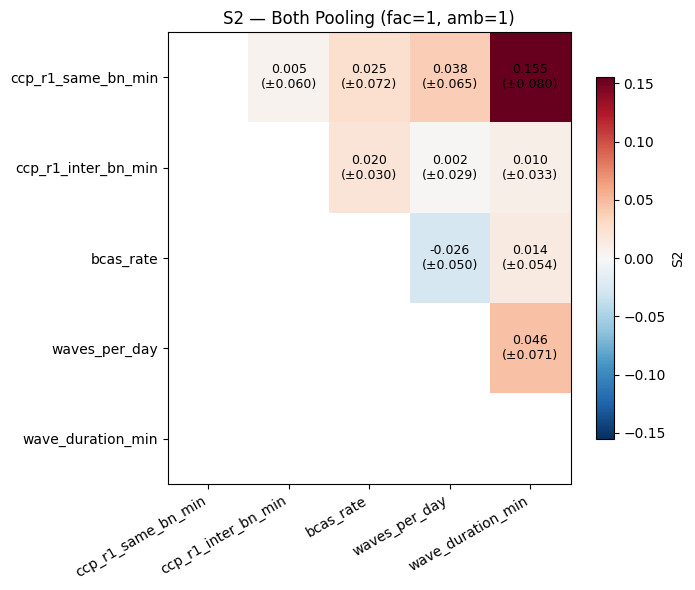

In [3]:
S2 = pd.DataFrame(Si["S2"], index=UNCERTAINTIES, columns=UNCERTAINTIES)
S2_conf = pd.DataFrame(Si["S2_conf"], index=UNCERTAINTIES, columns=UNCERTAINTIES)

fig, ax = plt.subplots(figsize=(7, 6))
mask = np.tril(np.ones_like(S2, dtype=bool), k=0)
s2_masked = S2.where(~mask)
vabs = max(0.01, np.nanmax(np.abs(s2_masked.values.astype(float))))
im = ax.imshow(s2_masked.values.astype(float), cmap="RdBu_r", vmin=-vabs, vmax=vabs, aspect="auto")
ax.set_xticks(range(len(UNCERTAINTIES)))
ax.set_xticklabels(UNCERTAINTIES, rotation=30, ha="right")
ax.set_yticks(range(len(UNCERTAINTIES)))
ax.set_yticklabels(UNCERTAINTIES)
ax.set_title("S2 — Both Pooling (fac=1, amb=1)")
for i in range(len(UNCERTAINTIES)):
    for j in range(len(UNCERTAINTIES)):
        if not mask[i, j]:
            v = S2.iloc[i, j]
            c = S2_conf.iloc[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:.3f}\n(±{c:.3f})", ha="center", va="center", fontsize=9)
plt.colorbar(im, ax=ax, shrink=0.8, label="S2")
plt.tight_layout()
plt.show()
